In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuration de l'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("Environnement d'analyse initialisé.")

Environnement d'analyse initialisé.


In [4]:
# Définition du chemin du projet
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "raw" / "AdventureWorks_Database.xlsx"

# Chargement des feuilles Excel
donnees = pd.read_excel(DATA_PATH, sheet_name=None)

# Extraction des tables
dim_date = donnees["Sheet2"]
dim_customer = donnees["Sheet3"]
dim_product = donnees["Sheet4"]
fact_sales = donnees["Sheet5"]
dim_territory = donnees["Sheet6"]

print("Chargement des données terminé.")

Chargement des données terminé.


In [5]:
# Regroupement des tables
tables = {
    "DimDate": dim_date,
    "DimCustomer": dim_customer,
    "DimProduct": dim_product,
    "FactInternetSales": fact_sales,
    "DimSalesTerritory": dim_territory
}

# Calcul des valeurs manquantes
resultats_manquants = []

for nom_table, df in tables.items():

    total_cellules = df.size
    total_manquants = df.isna().sum().sum()

    resultats_manquants.append({
        "Table": nom_table,
        "Nombre_lignes": len(df),
        "Nombre_colonnes": len(df.columns),
        "Valeurs_manquantes": total_manquants,
        "Pourcentage_manquant": (
            total_manquants / total_cellules * 100
        )
    })

bilan_manquants = pd.DataFrame(resultats_manquants)

display(bilan_manquants.round(2))

,Table,Nombre_lignes,Nombre_colonnes,Valeurs_manquantes,Pourcentage_manquant
0,DimDate,1461,16,0,0.00
1,DimCustomer,18484,17,566,0.18
2,DimProduct,606,13,1739,22.07
3,FactInternetSales,58189,13,0,0.00
4,DimSalesTerritory,11,5,3,5.45


# Analyse de DimCustomer

In [7]:
# Nombre et pourcentage de valeurs manquantes par colonne

manquants_clients = pd.DataFrame({
    "Valeurs_manquantes": dim_customer.isna().sum(),
    "Pourcentage_manquant": (
        dim_customer.isna().mean() * 100
    )
})

manquants_clients = (
    manquants_clients
    .query("Valeurs_manquantes > 0")
    .sort_values(
        by="Pourcentage_manquant",
        ascending=False
    )
)

display(manquants_clients.round(2))

,Valeurs_manquantes,Pourcentage_manquant
DateFirstPurchase,566,3.06


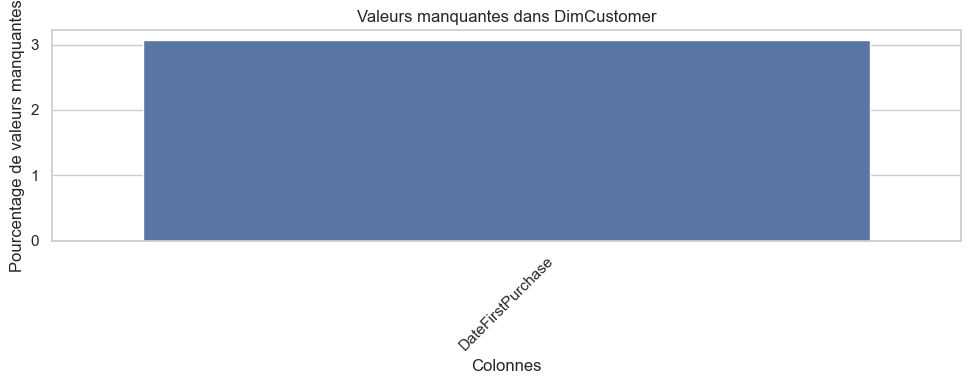

In [8]:
# Visualisation des valeurs manquantes

plt.figure(figsize=(10, 4))

sns.barplot(
    data=manquants_clients.reset_index(),
    x="index",
    y="Pourcentage_manquant"
)

plt.title("Valeurs manquantes dans DimCustomer")
plt.xlabel("Colonnes")
plt.ylabel("Pourcentage de valeurs manquantes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Identification des clients ayant effectué un achat Internet

clients_avec_achat = set(fact_sales["CustomerKey"].unique())

# Identification des clients sans achat Internet

clients_sans_achat = dim_customer[
    ~dim_customer["CustomerKey"].isin(clients_avec_achat)
]

# Identification des clients sans date de premier achat

clients_sans_date = dim_customer[
    dim_customer["DateFirstPurchase"].isna()
]

# Vérification de la correspondance

print("Clients sans achat Internet :", len(clients_sans_achat))
print("Clients sans date de premier achat :", len(clients_sans_date))

print(
    "Correspondance exacte :",
    set(clients_sans_achat["CustomerKey"])
    == set(clients_sans_date["CustomerKey"])
)

Clients sans achat Internet : 566
Clients sans date de premier achat : 566
Correspondance exacte : True


### Analyse de DateFirstPurchase — DimCustomer

La colonne `DateFirstPurchase` contient 566 valeurs manquantes, soit 3,06 % des clients.

Une comparaison avec les identifiants présents dans `FactInternetSales` a révélé une correspondance exacte entre :
- Les 566 clients absents de la table des ventes Internet.
- Les 566 clients sans date de premier achat.

Ces valeurs manquantes semblent donc liées à l'absence d'achat enregistré dans le canal de vente Internet.

**Décision :** conserver les valeurs manquantes à ce stade. Aucune imputation ni suppression n'est justifiée.

# Analyse de DimProduct

In [12]:
# Calcul des valeurs manquantes par colonne

manquants_produits = pd.DataFrame({
    "Valeurs_manquantes": dim_product.isna().sum(),
    "Pourcentage_manquant": dim_product.isna().mean() * 100
})

manquants_produits = (
    manquants_produits
    .query("Valeurs_manquantes > 0")
    .sort_values(
        by="Pourcentage_manquant",
        ascending=False
    )
)

display(manquants_produits.round(2))

,Valeurs_manquantes,Pourcentage_manquant
Color,254,41.91
ProductLine,226,37.29
StandardCost,211,34.82
ListPrice,211,34.82
ProductDescription,210,34.65
SubCategory,209,34.49
Category,209,34.49
ModelName,209,34.49


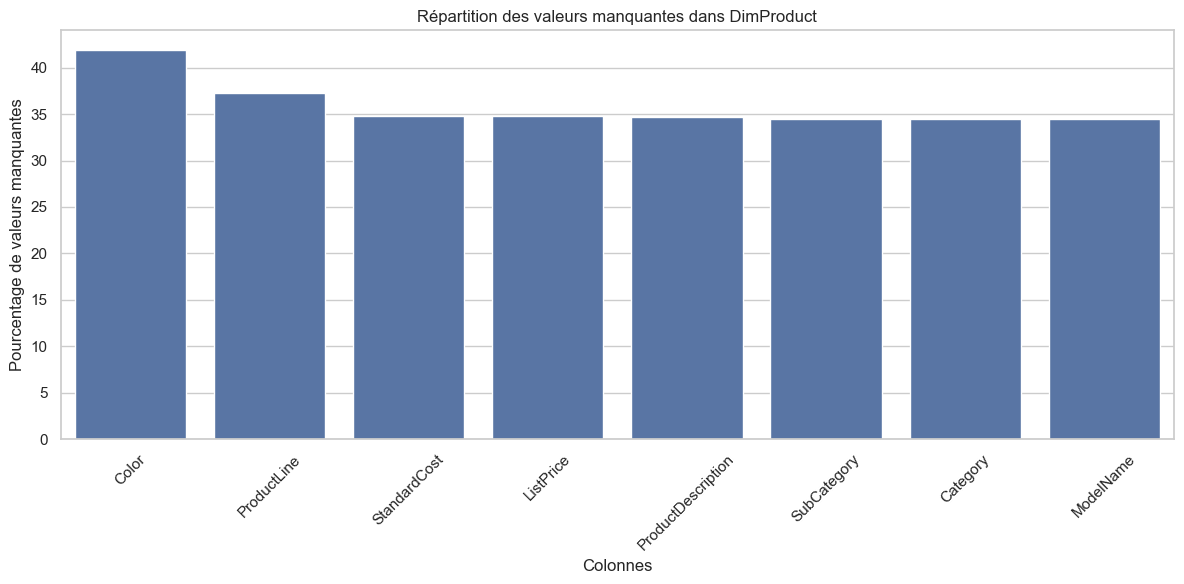

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=manquants_produits.reset_index(),
    x="index",
    y="Pourcentage_manquant"
)

plt.title("Répartition des valeurs manquantes dans DimProduct")
plt.xlabel("Colonnes")
plt.ylabel("Pourcentage de valeurs manquantes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
# Colonnes présentant des valeurs manquantes

colonnes_a_examiner = manquants_produits.index.tolist()

# Nombre de valeurs manquantes par produit

dim_product["Nombre_attributs_manquants"] = (
    dim_product[colonnes_a_examiner]
    .isna()
    .sum(axis=1)
)

# Répartition des produits selon le nombre d'attributs manquants

repartition_manquants = (
    dim_product["Nombre_attributs_manquants"]
    .value_counts()
    .sort_index()
    .reset_index()
)

repartition_manquants.columns = [
    "Nombre_attributs_manquants",
    "Nombre_produits"
]

display(repartition_manquants)

,Nombre_attributs_manquants,Nombre_produits
0,0,331
1,1,54
2,2,12
3,7,11
4,8,198


In [15]:
# Vérification des colonnes ayant exactement les mêmes valeurs manquantes

colonnes_a_comparer = [
    "SubCategory",
    "Category",
    "ModelName",
    "StandardCost",
    "ListPrice",
    "ProductDescription",
    "ProductLine",
    "Color"
]

# Comparaison des masques de valeurs manquantes

for colonne in colonnes_a_comparer:
    nombre_identiques = (
        dim_product[colonne].isna()
        == dim_product["SubCategory"].isna()
    ).sum()

    print(
        f"{colonne} : {nombre_identiques} lignes "
        f"avec le même statut que SubCategory"
    )

SubCategory : 606 lignes avec le même statut que SubCategory
Category : 606 lignes avec le même statut que SubCategory
ModelName : 606 lignes avec le même statut que SubCategory
StandardCost : 604 lignes avec le même statut que SubCategory
ListPrice : 604 lignes avec le même statut que SubCategory
ProductDescription : 605 lignes avec le même statut que SubCategory
ProductLine : 589 lignes avec le même statut que SubCategory
Color : 539 lignes avec le même statut que SubCategory


In [16]:
# Identification des produits vendus

produits_vendus = set(fact_sales["ProductKey"].unique())

# Identification des produits avec des informations manquantes

produits_incomplets = dim_product[
    dim_product["Nombre_attributs_manquants"] > 0
].copy()

produits_incomplets["Statut_vente"] = np.where(
    produits_incomplets["ProductKey"].isin(produits_vendus),
    "Vendu",
    "Non vendu"
)

# Synthèse des produits incomplets

synthese_produits = (
    produits_incomplets
    .groupby("Statut_vente")
    .agg(
        Nombre_produits=("ProductKey", "count"),
        Moyenne_attributs_manquants=(
            "Nombre_attributs_manquants",
            "mean"
        )
    )
    .reset_index()
)

display(synthese_produits.round(2))

,Statut_vente,Nombre_produits,Moyenne_attributs_manquants
0,Non vendu,257,6.7
1,Vendu,18,1.0


In [17]:
# Identifier les produits incomplets qui ont été vendus
produits_incomplets_vendus = produits_incomplets[
    produits_incomplets["Statut_vente"] == "Vendu"
].copy()

# Afficher les informations principales
colonnes_a_afficher = [
    "ProductKey",
    "ProductName",
    "SubCategory",
    "Category",
    "StandardCost",
    "ListPrice",
    "ProductLine",
    "Color",
    "ModelName",
    "Nombre_attributs_manquants"
]

display(
    produits_incomplets_vendus[colonnes_a_afficher]
    .sort_values("Nombre_attributs_manquants", ascending=False)
)

,ProductKey,ProductName,SubCategory,Category,StandardCost,ListPrice,ProductLine,Color,ModelName,Nombre_attributs_manquants
452,477,Water Bottle - 30 oz.,Bottles and Cages,Accessories,1.8663,4.99,Sport,NaN,Water Bottle,1
453,478,Mountain Bottle Cage,Bottles and Cages,Accessories,3.7363,9.99,Mountain,NaN,Mountain Bottle Cage,1
504,540,HL Road Tire,Tires and Tubes,Accessories,12.1924,32.60,Road,NaN,HL Road Tire,1
503,539,ML Road Tire,Tires and Tubes,Accessories,9.3463,24.99,Road,NaN,ML Road Tire,1
502,538,LL Road Tire,Tires and Tubes,Accessories,8.0373,21.49,Road,NaN,LL Road Tire,1
501,537,HL Mountain Tire,Tires and Tubes,Accessories,13.0900,35.00,Mountain,NaN,HL Mountain Tire,1
500,536,ML Mountain Tire,Tires and Tubes,Accessories,11.2163,29.99,Mountain,NaN,ML Mountain Tire,1
499,535,LL Mountain Tire,Tires and Tubes,Accessories,9.3463,24.99,Mountain,NaN,LL Mountain Tire,1
494,530,Touring Tire Tube,Tires and Tubes,Accessories,1.8663,4.99,Touring,NaN,Touring Tire Tube,1
493,529,Road Tire Tube,Tires and Tubes,Accessories,1.4923,3.99,Road,NaN,Road Tire Tube,1


In [18]:
# Identifier précisément les attributs manquants
colonnes_a_verifier = [
    "SubCategory",
    "Category",
    "StandardCost",
    "ListPrice",
    "ProductLine",
    "Color",
    "ModelName",
    "ProductDescription"
]

# Construire un tableau indiquant les attributs manquants
detail_manquants = produits_incomplets_vendus[
    ["ProductKey", "ProductName"]
].copy()

for colonne in colonnes_a_verifier:
    detail_manquants[colonne + "_manquant"] = (
        produits_incomplets_vendus[colonne].isna()
    )

display(detail_manquants)

,ProductKey,ProductName,SubCategory_manquant,Category_manquant,StandardCost_manquant,ListPrice_manquant,ProductLine_manquant,Color_manquant,ModelName_manquant,ProductDescription_manquant
452,477,Water Bottle - 30 oz.,False,False,False,False,False,True,False,False
453,478,Mountain Bottle Cage,False,False,False,False,False,True,False,False
454,479,Road Bottle Cage,False,False,False,False,False,True,False,False
455,480,Patch Kit/8 Patches,False,False,False,False,False,True,False,False
458,483,Hitch Rack - 4-Bike,False,False,False,False,False,True,False,False
459,484,Bike Wash - Dissolver,False,False,False,False,False,True,False,False
460,485,Fender Set - Mountain,False,False,False,False,False,True,False,False
461,486,All-Purpose Bike Stand,False,False,False,False,False,True,False,False
492,528,Mountain Tire Tube,False,False,False,False,False,True,False,False
493,529,Road Tire Tube,False,False,False,False,False,True,False,False


### Analyse des valeurs manquantes dans DimProduct

L'analyse des 606 produits révèle que 275 présentent au moins un attribut manquant.

Parmi ces 275 produits :
- 257 ne sont pas présents dans la table `FactInternetSales`.
- 18 ont été vendus et présentent chacun une seule valeur manquante : `ModelName`.

Les 18 produits vendus disposent de leurs informations commerciales essentielles, notamment le coût standard, le prix de vente, la catégorie et la sous-catégorie.

**Décision :** aucune suppression ni imputation automatique ne sera effectuée. Les valeurs manquantes seront conservées afin de préserver l'intégralité du catalogue et de ne pas introduire de données artificielles.

Cette décision permet de conserver les produits nécessaires aux analyses commerciales tout en respectant la structure initiale des données.

# Analyse de DimSalesTerritory

In [21]:
# Identifier les lignes présentant des valeurs manquantes
territoires_incomplets = dim_territory[
    dim_territory.isna().any(axis=1)
]

display(territoires_incomplets)

,SalesTerritoryKey,Region,Country,Group,RegionImage
10,11,NaN,NaN,NaN,http://www.avising.com/me/LearnPBI/DataSources...


In [22]:
# Vérifier l'utilisation du territoire 10 dans les ventes
ventes_territoire_10 = fact_sales[
    fact_sales["SalesTerritoryKey"] == 10
]

print("Nombre de lignes de vente :", len(ventes_territoire_10))
print(
    "Nombre de commandes :",
    ventes_territoire_10["SalesOrderNumber"].nunique()
)
print(
    "Chiffre d'affaires :",
    ventes_territoire_10["SalesAmount"].sum()
)

Nombre de lignes de vente : 6709
Nombre de commandes : 2947
Chiffre d'affaires : 3387490.800899999


In [23]:
# Afficher les territoires pour comparer leurs informations
display(
    dim_territory.sort_values("SalesTerritoryKey")
)

,SalesTerritoryKey,Region,Country,Group,RegionImage
0,1,Northwest,United States,North America,http://www.avising.com/me/LearnPBI/DataSources...
1,2,Northeast,United States,North America,http://www.avising.com/me/LearnPBI/DataSources...
2,3,Central,United States,North America,http://www.avising.com/me/LearnPBI/DataSources...
3,4,Southwest,United States,North America,http://www.avising.com/me/LearnPBI/DataSources...
4,5,Southeast,United States,North America,http://www.avising.com/me/LearnPBI/DataSources...
5,6,Canada,Canada,North America,http://www.avising.com/me/LearnPBI/DataSources...
6,7,France,France,Europe,http://www.avising.com/me/LearnPBI/DataSources...
7,8,Germany,Germany,Europe,http://www.avising.com/me/LearnPBI/DataSources...
8,9,Australia,Australia,Pacific,http://www.avising.com/me/LearnPBI/DataSources...
9,10,United Kingdom,United Kingdom,Europe,http://www.avising.com/me/LearnPBI/DataSources...


### Analyse des valeurs manquantes dans DimSalesTerritory

L'analyse de la dimension géographique révèle une seule ligne incomplète, correspondant à `SalesTerritoryKey = 10`.

Les colonnes `Country` et `Group` sont manquantes, tandis que `Region` est renseignée.

La vérification dans `FactInternetSales` montre que ce territoire est associé à :
- 6 709 lignes de vente ;
- 2 947 commandes distinctes ;
- un chiffre d'affaires de 3 387 490,80.

Ce territoire représente environ 11,7 % du chiffre d'affaires total. Il ne peut donc pas être ignoré dans les analyses.

**Décision :** conserver la ligne et les valeurs manquantes. Aucune imputation ne sera effectuée sans information fiable permettant d'identifier le pays et le groupe. Dans les visualisations géographiques, les valeurs absentes pourront être présentées sous la catégorie « Non renseigné ».

In [25]:
# Vérifier les doublons complets dans chaque table
tables = {
    "DimDate": dim_date,
    "DimCustomer": dim_customer,
    "DimProduct": dim_product,
    "FactInternetSales": fact_sales,
    "DimSalesTerritory": dim_territory
}

for nom, df in tables.items():
    print(f"{nom} : {df.duplicated().sum()} doublon(s)")

DimDate : 0 doublon(s)
DimCustomer : 0 doublon(s)
DimProduct : 0 doublon(s)
FactInternetSales : 0 doublon(s)
DimSalesTerritory : 0 doublon(s)


### Vérification des doublons complets

La vérification des cinq tables ne révèle aucun doublon complet.

| Table | Doublons |
|---|---:|
| DimDate | 0 |
| DimCustomer | 0 |
| DimProduct | 0 |
| FactInternetSales | 0 |
| DimSalesTerritory | 0 |

**Décision :** aucune suppression de ligne n'est nécessaire sur la base des doublons complets.

Cette vérification ne permet toutefois pas d'exclure les doublons métier, qui seront examinés séparément à travers les clés et les règles de gestion.

In [27]:
# Vérifier l'unicité et les valeurs manquantes des clés primaires
cles_primaires = {
    "DimDate": ("DateKey", dim_date),
    "DimCustomer": ("CustomerKey", dim_customer),
    "DimProduct": ("ProductKey", dim_product),
    "DimSalesTerritory": ("SalesTerritoryKey", dim_territory)
}

for nom_table, (colonne, df) in cles_primaires.items():
    print(f"\n--- {nom_table} ---")
    print("Nombre de lignes :", len(df))
    print("Valeurs uniques :", df[colonne].nunique())
    print("Valeurs manquantes :", df[colonne].isna().sum())
    print("Doublons :", df[colonne].duplicated().sum())


--- DimDate ---
Nombre de lignes : 1461
Valeurs uniques : 1461
Valeurs manquantes : 0
Doublons : 0

--- DimCustomer ---
Nombre de lignes : 18484
Valeurs uniques : 18484
Valeurs manquantes : 0
Doublons : 0

--- DimProduct ---
Nombre de lignes : 606
Valeurs uniques : 606
Valeurs manquantes : 0
Doublons : 0

--- DimSalesTerritory ---
Nombre de lignes : 11
Valeurs uniques : 11
Valeurs manquantes : 0
Doublons : 0


### Vérification des clés primaires

Les quatre dimensions ont été contrôlées afin de vérifier l'unicité et l'intégrité de leurs identifiants.

Les résultats montrent que :
- toutes les clés primaires sont renseignées ;
- aucune clé primaire n'est dupliquée ;
- le nombre de valeurs uniques correspond au nombre total de lignes dans chaque dimension.

**Décision :** aucune correction des clés primaires n'est nécessaire. Les quatre dimensions respectent les contraintes d'unicité et de non-nullité.

In [29]:
# Définir les relations entre la table de faits et les dimensions
relations = {
    "ProductKey": dim_product,
    "CustomerKey": dim_customer,
    "SalesTerritoryKey": dim_territory
}

# Vérifier les clés étrangères
for colonne, dimension in relations.items():

    cles_dimension = set(dimension[colonne].dropna())

    cles_faits = set(fact_sales[colonne].dropna())

    cles_orphelines = cles_faits - cles_dimension

    print(f"\n--- {colonne} ---")
    print("Identifiants distincts dans les ventes :", len(cles_faits))
    print("Identifiants dans la dimension :", len(cles_dimension))
    print("Clés étrangères orphelines :", len(cles_orphelines))


--- ProductKey ---
Identifiants distincts dans les ventes : 158
Identifiants dans la dimension : 606
Clés étrangères orphelines : 0

--- CustomerKey ---
Identifiants distincts dans les ventes : 17918
Identifiants dans la dimension : 18484
Clés étrangères orphelines : 0

--- SalesTerritoryKey ---
Identifiants distincts dans les ventes : 10
Identifiants dans la dimension : 11
Clés étrangères orphelines : 0


### Vérification de l'intégrité référentielle

Le contrôle des clés étrangères de `FactInternetSales` a été effectué sur trois relations :

| Clé étrangère | Identifiants dans les ventes | Identifiants dans la dimension | Clés orphelines |
|---|---:|---:|---:|
| ProductKey | 158 | 606 | 0 |
| CustomerKey | 17 918 | 18 484 | 0 |
| SalesTerritoryKey | 10 | 11 | 0 |

Les résultats montrent qu'aucun identifiant présent dans la table de faits ne manque dans sa dimension de référence.

**Décision :** aucune correction des clés étrangères n'est nécessaire. Les relations entre la table de faits et les trois dimensions respectent l'intégrité référentielle.

In [54]:
# Vérifier la cohérence des dates de commande et d'expédition

print("Dates de commande manquantes :",
      fact_sales["OrderDate"].isna().sum())

print("Dates d'expédition manquantes :",
      fact_sales["ShipDate"].isna().sum())

# Identifier les expéditions antérieures aux commandes
expeditions_invalides = fact_sales[
    fact_sales["ShipDate"] < fact_sales["OrderDate"]
]

print("Expéditions antérieures aux commandes :",
      len(expeditions_invalides))

Dates de commande manquantes : 0
Dates d'expédition manquantes : 0
Expéditions antérieures aux commandes : 0


### Contrôle de cohérence des dates

Les colonnes `OrderDate` et `ShipDate` ont été contrôlées afin de détecter les dates manquantes et les incohérences chronologiques.

Résultats :
- 0 date de commande manquante ;
- 0 date d'expédition manquante ;
- 0 expédition antérieure à la date de commande.

**Décision :** aucune correction n'est nécessaire. Les dates de commande et d'expédition respectent les règles de cohérence temporelle vérifiées.

In [60]:
# Vérifier les valeurs incohérentes dans les quantités et les prix
colonnes_numeriques = [
    "OrderQuantity",
    "UnitPrice",
    "TotalProductCost"
]

for colonne in colonnes_numeriques:

    print(f"\n--- {colonne} ---")
    print("Valeurs manquantes :", fact_sales[colonne].isna().sum())
    print("Valeurs égales à zéro :", (fact_sales[colonne] == 0).sum())
    print("Valeurs négatives :", (fact_sales[colonne] < 0).sum())


--- OrderQuantity ---
Valeurs manquantes : 0
Valeurs égales à zéro : 0
Valeurs négatives : 0

--- UnitPrice ---
Valeurs manquantes : 0
Valeurs égales à zéro : 0
Valeurs négatives : 0

--- TotalProductCost ---
Valeurs manquantes : 0
Valeurs égales à zéro : 0
Valeurs négatives : 0


### Contrôle des quantités et des prix

Les colonnes `OrderQuantity`, `UnitPrice` et `TotalProductCost` ont été examinées afin de détecter les valeurs manquantes, nulles ou négatives.

Les résultats montrent :
- aucune valeur manquante ;
- aucune valeur égale à zéro ;
- aucune valeur négative.

**Décision :** aucune correction n'est nécessaire pour ces trois colonnes. Toutes les valeurs respectent les contrôles élémentaires de validité numérique.

In [66]:
# Calculer le chiffre d'affaires théorique de chaque ligne
fact_sales["SalesAmount_Calcule"] = (
    fact_sales["OrderQuantity"] * fact_sales["UnitPrice"]
)

# Calculer l'écart avec le chiffre d'affaires enregistré
fact_sales["Ecart_SalesAmount"] = (
    fact_sales["SalesAmount"] - fact_sales["SalesAmount_Calcule"]
)

# Identifier les lignes présentant un écart
ecarts_ventes = fact_sales[
    ~np.isclose(
        fact_sales["SalesAmount"],
        fact_sales["SalesAmount_Calcule"],
        rtol=1e-9,
        atol=0.01
    )
]

print("Nombre de lignes avec un écart :", len(ecarts_ventes))

Nombre de lignes avec un écart : 0


### Vérification du calcul du chiffre d'affaires

Le montant `SalesAmount` a été comparé au montant théorique calculé selon la formule :

`SalesAmount = OrderQuantity × UnitPrice`

Une tolérance de 0,01 a été appliquée afin de tenir compte des éventuelles différences d'arrondi.

Résultat :
- 58 189 lignes contrôlées ;
- 0 ligne présentant un écart supérieur à la tolérance.

**Décision :** aucune incohérence détectée. Le chiffre d'affaires enregistré est cohérent avec les quantités commandées et les prix unitaires.

In [72]:
# Récupérer le coût standard depuis la dimension produit
controle_couts = fact_sales.merge(
    dim_product[["ProductKey", "StandardCost"]],
    on="ProductKey",
    how="left"
)

# Calculer le coût total théorique
controle_couts["TotalProductCost_Calcule"] = (
    controle_couts["OrderQuantity"]
    * controle_couts["StandardCost"]
)

# Calculer l'écart entre le coût enregistré et le coût calculé
controle_couts["Ecart_Cout"] = (
    controle_couts["TotalProductCost"]
    - controle_couts["TotalProductCost_Calcule"]
)

# Identifier les lignes présentant un écart
ecarts_couts = controle_couts[
    ~np.isclose(
        controle_couts["TotalProductCost"],
        controle_couts["TotalProductCost_Calcule"],
        rtol=1e-9,
        atol=0.01,
        equal_nan=False
    )
]

print("Nombre de lignes avec un écart :", len(ecarts_couts))
print(
    "Nombre de lignes sans coût standard :",
    controle_couts["StandardCost"].isna().sum()
)

Nombre de lignes avec un écart : 16604
Nombre de lignes sans coût standard : 0


In [76]:
# Examiner la distribution des écarts de coût
print("Écart moyen :", ecarts_couts["Ecart_Cout"].mean())
print("Écart médian :", ecarts_couts["Ecart_Cout"].median())
print("Écart minimum :", ecarts_couts["Ecart_Cout"].min())
print("Écart maximum :", ecarts_couts["Ecart_Cout"].max())

# Afficher quelques lignes présentant un écart
display(
    ecarts_couts[
        [
            "ProductKey",
            "OrderQuantity",
            "StandardCost",
            "TotalProductCost",
            "TotalProductCost_Calcule",
            "Ecart_Cout"
        ]
    ].head(10)
)

Écart moyen : -591.3130542158515
Écart médian : -23.749
Écart minimum : -6513.882599999999
Écart maximum : -0.8565


,ProductKey,OrderQuantity,StandardCost,TotalProductCost,TotalProductCost_Calcule,Ecart_Cout
0,310,2,2171.2942,2171.2942,4342.5884,-2171.2942
1,346,2,1912.1544,1912.1544,3824.3088,-1912.1544
2,346,2,1912.1544,1912.1544,3824.3088,-1912.1544
3,336,2,413.1463,413.1463,826.2926,-413.1463
4,346,2,1912.1544,1912.1544,3824.3088,-1912.1544
5,311,4,2171.2942,2171.2942,8685.1768,-6513.8826
6,310,4,2171.2942,2171.2942,8685.1768,-6513.8826
7,351,4,1898.0944,1898.0944,7592.3776,-5694.2832
8,344,4,1912.1544,1912.1544,7648.6176,-5736.4632
28,311,2,2171.2942,2171.2942,4342.5884,-2171.2942


In [80]:
# Comparer le coût enregistré au coût standard du produit
controle_couts["Ecart_StandardCost"] = (
    controle_couts["TotalProductCost"]
    - controle_couts["StandardCost"]
)

print(
    "Lignes où TotalProductCost = StandardCost :",
    np.isclose(
        controle_couts["TotalProductCost"],
        controle_couts["StandardCost"],
        atol=0.01
    ).sum()
)

print(
    "Lignes où les deux coûts sont différents :",
    (~np.isclose(
        controle_couts["TotalProductCost"],
        controle_couts["StandardCost"],
        atol=0.01
    )).sum()
)

# Examiner les résultats selon la quantité commandée
display(
    controle_couts
    .groupby("OrderQuantity")
    .agg(
        Nombre_lignes=("ProductKey", "size"),
        Cout_moyen_enregistre=("TotalProductCost", "mean"),
        Cout_standard_moyen=("StandardCost", "mean")
    )
    .round(4)
    .head(10)
)

Lignes où TotalProductCost = StandardCost : 58189
Lignes où les deux coûts sont différents : 0


,Nombre_lignes,Cout_moyen_enregistre,Cout_standard_moyen
OrderQuantity,,,
1,41585,296.2993,296.2993
2,8340,298.7395,298.7395
4,8264,295.5258,295.5258


In [84]:
# Calculer le coût total réel estimé de chaque ligne
controle_couts["CalculatedTotalCost"] = (
    controle_couts["OrderQuantity"]
    * controle_couts["StandardCost"]
)

### Vérification de la cohérence du coût total des produits

Le champ `TotalProductCost` a été comparé au coût total théorique calculé selon la formule :

`OrderQuantity × StandardCost`

Le contrôle a révélé 16 604 lignes présentant un écart.

Une investigation complémentaire a ensuite montré que `TotalProductCost` est strictement égal à `StandardCost` sur les 58 189 lignes, indépendamment de la quantité commandée.

Cette observation révèle une incohérence entre le nom de la colonne et son contenu : la colonne `TotalProductCost` contient le coût standard unitaire plutôt que le coût total de la ligne.

**Décision :**
- conserver la colonne originale `TotalProductCost` pour préserver la traçabilité ;
- créer une nouvelle colonne `CalculatedTotalCost` calculée à partir de `OrderQuantity × StandardCost` ;
- utiliser cette nouvelle colonne pour les analyses de coûts et de rentabilité, en précisant qu'il s'agit d'un coût total estimé à partir du coût standard.

In [90]:
# Examiner les statistiques descriptives des montants financiers
colonnes_financieres = [
    "SalesAmount",
    "TotalProductCost",
    "TaxAmt"
]

display(
    fact_sales[colonnes_financieres].describe().round(2)
)

,SalesAmount,TotalProductCost,TaxAmt
count,58189.00,58189.00,58189.00
mean,503.67,296.54,40.29
std,941.46,560.17,75.32
min,2.29,0.86,0.18
25%,8.99,3.36,0.72
50%,32.60,12.19,2.61
75%,539.99,343.65,43.20
max,3578.27,2171.29,286.26


In [94]:
# Calculer le taux de taxe appliqué à chaque ligne de vente
fact_sales["TaxRate_Calcule"] = (
    fact_sales["TaxAmt"] / fact_sales["SalesAmount"]
) * 100

# Examiner la distribution des taux de taxe
display(
    fact_sales["TaxRate_Calcule"]
    .describe()
    .round(4)
)

# Identifier les taux de taxe distincts
display(
    fact_sales["TaxRate_Calcule"]
    .round(2)
    .value_counts()
    .sort_index()
    .to_frame("Nombre de lignes")
)

count    58189.0
mean         8.0
std          0.0
min          8.0
25%          8.0
50%          8.0
75%          8.0
max          8.0
Name: TaxRate_Calcule, dtype: float64

,Nombre de lignes
TaxRate_Calcule,
8.0,58189


#### Vérification de la cohérence de la taxe

Le taux de taxe a été calculé pour chaque ligne à partir du rapport entre `TaxAmt` et `SalesAmount`.

Les résultats montrent que :

- Les 58 189 lignes présentent un taux de taxe de 8 %.
- Aucun écart n'a été observé entre les lignes.
- L'écart-type du taux calculé est nul.

**Décision :** la colonne `TaxAmt` est cohérente avec l'application d'un taux uniforme de 8 % sur `SalesAmount`. Aucune correction n'est nécessaire.

#  Conclusion – Audit de la qualité des données

L'audit de qualité a porté sur les cinq tables du projet AdventureWorks : `DimDate`, `DimCustomer`, `DimProduct`, `DimSalesTerritory` et `FactInternetSales`.

Les contrôles ont couvert les valeurs manquantes, les doublons, l'intégrité des clés primaires et étrangères, la cohérence des dates, les valeurs numériques et les règles de calcul des principaux indicateurs financiers.

### Résultats principaux

- Aucune ligne entièrement dupliquée n'a été détectée.
- Toutes les clés primaires sont uniques et sans valeur manquante.
- Aucune clé étrangère orpheline n'a été identifiée dans la table de faits.
- Les dates de commande et d'expédition sont cohérentes.
- Les quantités, prix unitaires et coûts contrôlés sont strictement positifs.
- `SalesAmount` respecte la formule `OrderQuantity × UnitPrice`.
- `TaxAmt` correspond à un taux uniforme de 8 % de `SalesAmount`.

### Particularités identifiées

Plusieurs informations manquantes ont été relevées dans les dimensions clients, produits et territoires. Elles ont été conservées afin de préserver l'intégrité des données.

Une particularité concerne également `TotalProductCost`, qui correspond exactement à `StandardCost` sur toutes les lignes de vente, sans tenir compte des quantités commandées.

Pour les analyses financières, une nouvelle variable `CalculatedTotalCost` sera créée à partir de `OrderQuantity × StandardCost`, sans modifier la colonne originale.

### Décision finale

La qualité globale des données est satisfaisante pour poursuivre le projet.

Les données sources seront conservées. Les transformations nécessaires seront appliquées dans une étape distincte, avec une traçabilité des modifications et une attention particulière aux informations manquantes et aux calculs financiers.

**Prochaine étape :** préparation des données et création des tables exploitables pour les analyses exploratoires et la modélisation Power BI.